# Aviation Accidents Analysis - Data Analysis

Part Two of the project. The cleaned data from the cleaning notebook is loaded, aircraft are split into **small** and **large**, and make/model safety is compared with explicit sample-size rules and confidence intervals. Two further factors (weather condition and engine type) are then examined with statistical tests.

**Measures used throughout**
- `fatal_serious_fraction`: (fatal + serious injuries) / estimated occupants in an accident. Lower is safer.
- `destroyed`: 1 if the aircraft was destroyed, 0 if it had substantial or minor damage. Lower is safer.

**Method rules (so every claim is robust)**
1. A make must have **at least 30 accidents with a known outcome** inside its size group to be ranked; a model needs **at least 10**, counted *inside* its size group.
2. Every mean is shown with a **95% bootstrap confidence interval**. A difference is only called real when the intervals or a statistical test support it.
3. All figures are **conditional on an accident having occurred**. Nothing here is a per-flight risk, because the data holds no flight counts.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 110

os.makedirs('images', exist_ok=True)
def save(fig, name):
    fig.savefig(f'images/{name}.png', bbox_inches='tight', dpi=150)

## STEP 1: Load in the cleaned data

In [2]:
path = 'data/aviation_cleaned.csv'
df = pd.read_csv(path, parse_dates=['Event.Date'], low_memory=False)
print('Loaded', path, '->', df.shape)
print('Injury fraction known :', df['fatal_serious_fraction'].notna().sum())
print('Destroyed known       :', df['destroyed'].notna().sum())
print('Event dates           :', df['Event.Date'].min().date(), 'to', df['Event.Date'].max().date())

Loaded data/aviation_cleaned.csv -> (18072, 37)
Injury fraction known : 17281
Destroyed known       : 16907
Event dates           : 1983-03-18 to 2022-12-26


## STEP 2: Explore safety metrics across models/makes

### Separating small and large aircraft (threshold = 20)

The brief asks for a passenger threshold of 20. The cleaned data only holds *how many people were on board each accident flight*, not seat capacity. Splitting **each accident** on that number is misleading: the same Boeing 737 would count as "small" when an accident involved only crew.

Instead each **aircraft type (`make_model`) is classified once**:
- **Large** if the 90th percentile of its recorded occupancy is above 20, *or* at least **two** recorded accidents had more than 100 people on board (this catches freighters such as the 747, whose accidents often involved crew only). Requiring two accidents makes the rule robust to a single data-entry error: one Cessna 172M record lists 124 occupants, and a "one accident over 100" rule would have wrongly reclassified all 180 of that type as large aircraft.
- **Small** otherwise.
- One documented manual override: the **McDonnell Douglas MD-11** (a widebody freighter/airliner whose accidents are mostly crew-only) is set to Large.

Every accident then inherits its aircraft type's class.

In [3]:
occ = df[df['occupants_est'] > 0].groupby('make_model')['occupants_est'].agg(
    p90=lambda s: s.quantile(0.9), n_over_100=lambda s: (s > 100).sum())
occ['size'] = np.where((occ['p90'] > 20) | (occ['n_over_100'] >= 2), 'Large', 'Small')
MANUAL_LARGE = ['MCDONNELL DOUGLAS MD11']          # documented override (freighter, crew-only accidents)
occ.loc[occ.index.isin(MANUAL_LARGE), 'size'] = 'Large'

df['size'] = df['make_model'].map(occ['size'])
# types with no accident that has a positive occupant count: fall back to the accident itself
fallback = df['size'].isna()
df.loc[fallback, 'size'] = np.where(df.loc[fallback, 'occupants_est'] > 20, 'Large', 'Small')

print(df['size'].value_counts().to_string())
print()
print('Sanity check - how the well-known types were classified:')
for k in ['BOEING 737', 'BOEING 747', 'AIRBUS A320', 'MCDONNELL DOUGLAS MD11', 'CESSNA 172M', 'CESSNA 208', 'BEECH 1900']:
    print(f'  {k:26s}', occ['size'].get(k, 'n/a'))

small = df[df['size'] == 'Small'].copy()
large = df[df['size'] == 'Large'].copy()

size
Small    16507
Large     1565

Sanity check - how the well-known types were classified:
  BOEING 737                 Large
  BOEING 747                 Large
  AIRBUS A320                Large
  MCDONNELL DOUGLAS MD11     Large
  CESSNA 172M                Small
  CESSNA 208                 Small
  BEECH 1900                 Small


### Helper functions: group means with confidence intervals and minimum sample sizes

In [4]:
RNG = np.random.default_rng(42)

def boot_ci(values, n_boot=2000, alpha=0.05):
    x = np.asarray(values, dtype=float)
    idx = RNG.integers(0, len(x), size=(n_boot, len(x)))
    means = x[idx].mean(axis=1)
    return np.percentile(means, [100 * alpha / 2, 100 * (1 - alpha / 2)])

def group_table(data, group_col, value_col, min_n):
    """Mean, n and 95% CI of value_col per group, keeping groups with n >= min_n known values."""
    d = data.dropna(subset=[value_col])
    g = d.groupby(group_col)[value_col].agg(mean='mean', median='median', n='count')
    g = g[g['n'] >= min_n].sort_values('mean')
    cis = {k: boot_ci(d.loc[d[group_col] == k, value_col]) for k in g.index}
    g['ci_low'] = [cis[k][0] for k in g.index]
    g['ci_high'] = [cis[k][1] for k in g.index]
    base = d[value_col].mean()
    g['better_than_group_avg'] = g['ci_high'] < base      # whole CI below the size-group average
    return g, base

def barh_ci(ax, tab, title, xlabel, color):
    y = np.arange(len(tab))
    err = [tab['mean'] - tab['ci_low'], tab['ci_high'] - tab['mean']]
    ax.barh(y, tab['mean'], xerr=err, color=color, alpha=0.85, capsize=3, ecolor='black')
    ax.set_yticks(y)
    ax.set_yticklabels([f'{i}  (n={n})' for i, n in zip(tab.index, tab['n'])])
    ax.invert_yaxis()
    ax.set_title(title); ax.set_xlabel(xlabel)

MIN_MAKE_N = 30
MIN_MODEL_N = 10

### 2.1 Analyzing makes: lowest mean fatal/serious injury fraction
Makes need at least 30 accidents with a known injury outcome in the size group. Bars show the mean with its 95% confidence interval; the label gives the sample size.

Small: 29 makes qualify (n >= 30); group average = 0.289
Large: 5 makes qualify (n >= 30); group average = 0.068


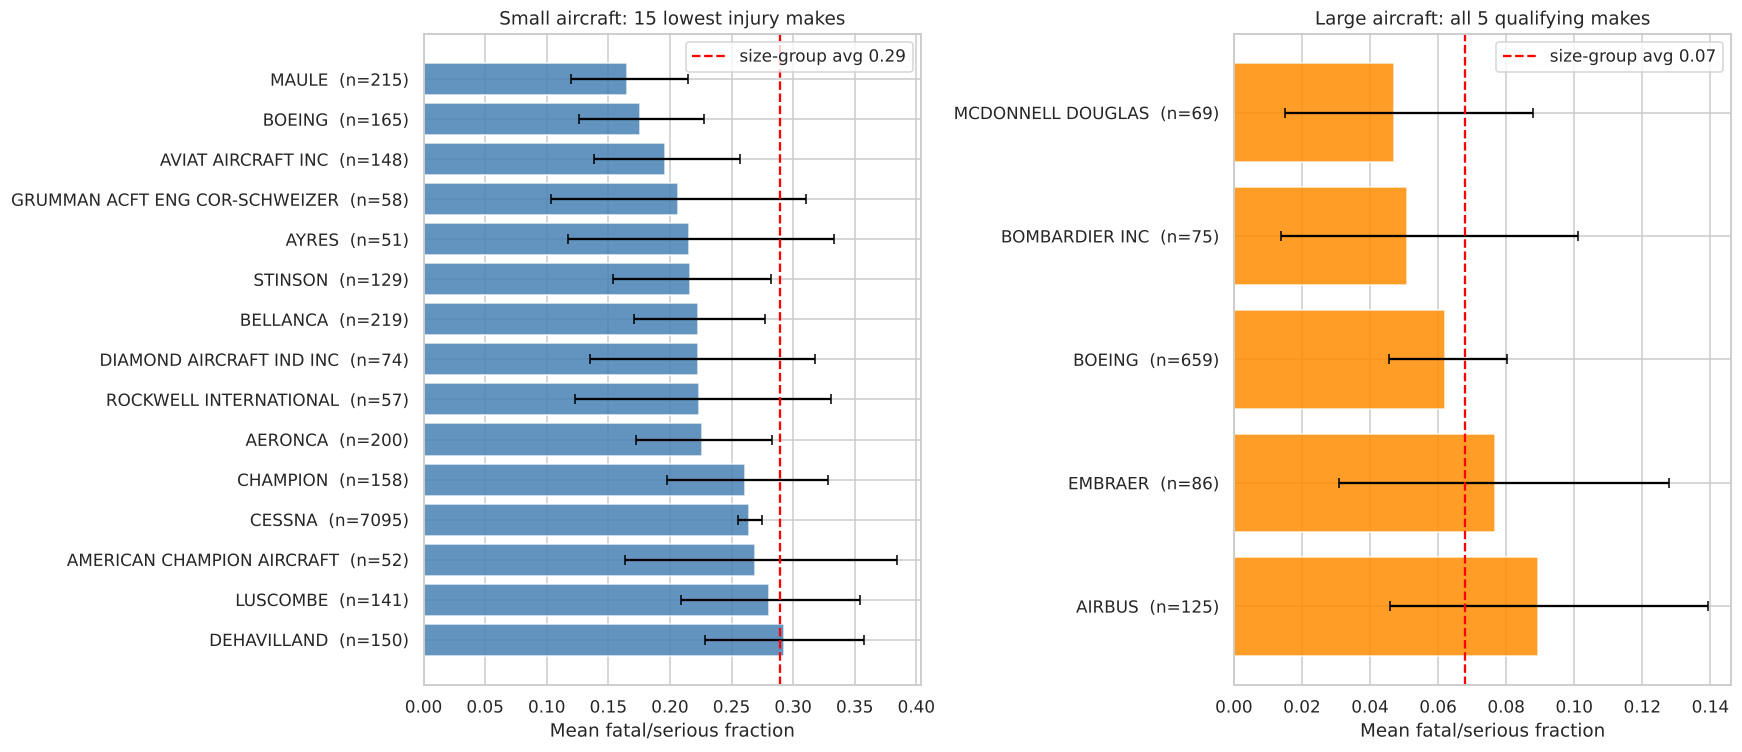

,mean,median,n,ci_low,ci_high,better_than_group_avg
Make_clean,,,,,,
MAULE,0.165,0.0,215,0.119,0.214,True
BOEING,0.176,0.0,165,0.126,0.228,True
AVIAT AIRCRAFT INC,0.196,0.0,148,0.139,0.257,True
GRUMMAN ACFT ENG COR-SCHWEIZER,0.207,0.0,58,0.103,0.310,False
AYRES,0.216,0.0,51,0.118,0.333,False
STINSON,0.216,0.0,129,0.154,0.282,True
BELLANCA,0.223,0.0,219,0.171,0.277,True
DIAMOND AIRCRAFT IND INC,0.223,0.0,74,0.135,0.318,False
ROCKWELL INTERNATIONAL,0.224,0.0,57,0.123,0.330,False


,mean,median,n,ci_low,ci_high,better_than_group_avg
Make_clean,,,,,,
MCDONNELL DOUGLAS,0.047,0.0,69,0.015,0.088,False
BOMBARDIER INC,0.051,0.0,75,0.014,0.101,False
BOEING,0.062,0.0,659,0.045,0.080,False
EMBRAER,0.077,0.0,86,0.031,0.128,False
AIRBUS,0.089,0.0,125,0.046,0.139,False


Where the two biggest small-aircraft makes sit:
             mean  count
Make_clean              
CESSNA      0.265   7095
PIPER       0.295   3988
Cessna share of small-aircraft accidents: 43.5%
Rank of Cessna / Piper among the 29 qualifying small makes: {'CESSNA': 12, 'PIPER': 16}

What "BOEING" means inside the SMALL group (top aircraft types):
make_model
BOEING A75N1(PT17)    31
BOEING B75N1          19
BOEING A75N1          16
BOEING E75             9
BOEING B75             5


In [5]:
small_inj, small_base = group_table(small, 'Make_clean', 'fatal_serious_fraction', MIN_MAKE_N)
large_inj, large_base = group_table(large, 'Make_clean', 'fatal_serious_fraction', MIN_MAKE_N)

print(f'Small: {len(small_inj)} makes qualify (n >= {MIN_MAKE_N}); group average = {small_base:.3f}')
print(f'Large: {len(large_inj)} makes qualify (n >= {MIN_MAKE_N}); group average = {large_base:.3f}')

small_top15 = small_inj.head(15)
large_top = large_inj.head(15)      # fewer than 15 exist; all qualifying makes are shown

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
barh_ci(axes[0], small_top15, 'Small aircraft: 15 lowest injury makes', 'Mean fatal/serious fraction', 'steelblue')
axes[0].axvline(small_base, color='red', ls='--', label=f'size-group avg {small_base:.2f}'); axes[0].legend()
barh_ci(axes[1], large_top, f'Large aircraft: all {len(large_top)} qualifying makes', 'Mean fatal/serious fraction', 'darkorange')
axes[1].axvline(large_base, color='red', ls='--', label=f'size-group avg {large_base:.2f}'); axes[1].legend()
plt.tight_layout(); save(fig, 'makes_injury_fraction'); plt.show()

display(small_top15.round(3))
display(large_top.round(3))

print('Where the two biggest small-aircraft makes sit:')
big = small.dropna(subset=['fatal_serious_fraction']).groupby('Make_clean')['fatal_serious_fraction'].agg(['mean', 'count'])
print(big.loc[['CESSNA', 'PIPER']].round(3).to_string())
print('Cessna share of small-aircraft accidents: %.1f%%' % ((small['Make_clean'] == 'CESSNA').mean() * 100))
print('Rank of Cessna / Piper among the', len(small_inj), 'qualifying small makes:',
      {m: int(small_inj['mean'].rank().get(m)) for m in ['CESSNA', 'PIPER']})
print()
print('What "BOEING" means inside the SMALL group (top aircraft types):')
print(small.loc[small['Make_clean'] == 'BOEING', 'make_model'].value_counts().head(5).to_string())

### 2.2 Distribution of injury rates: small makes (violin plot, 10 lowest means)

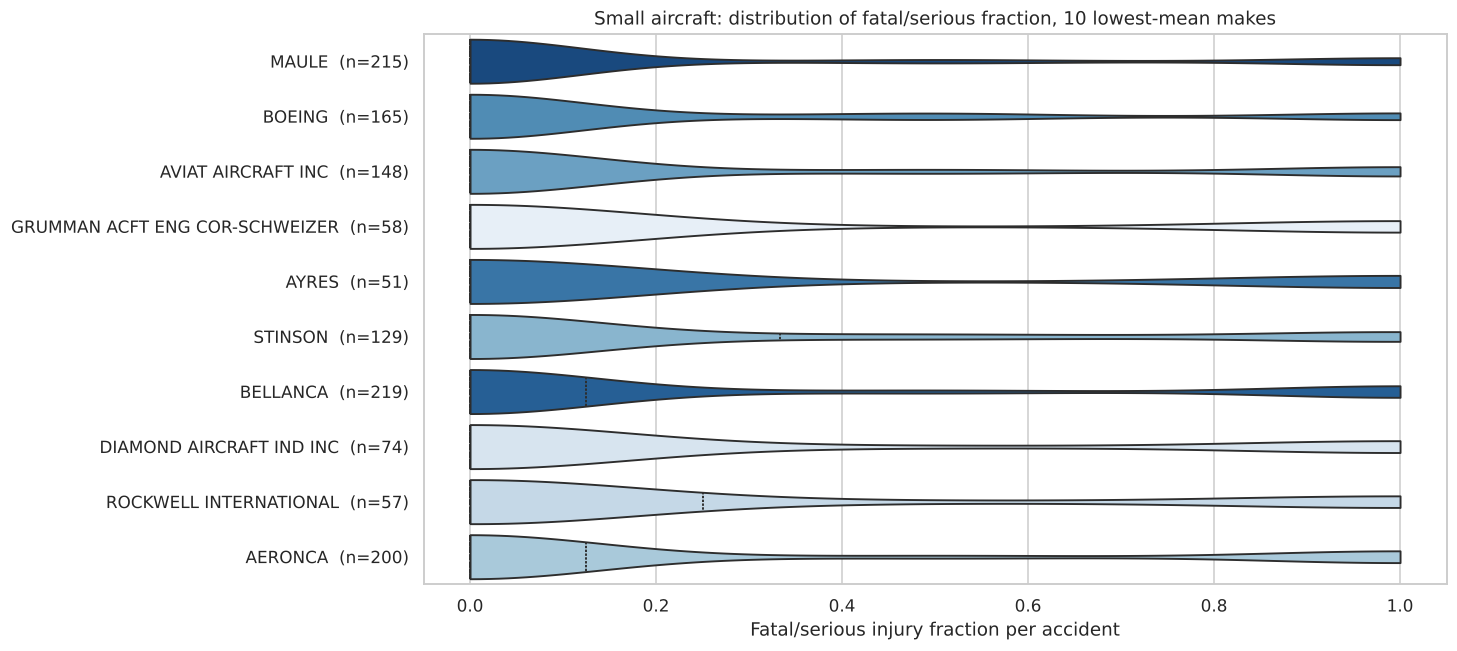

Share of accidents with zero fatal/serious injuries:
Make_clean
MAULE                             0.800
BOEING                            0.752
AVIAT AIRCRAFT INC                0.770
GRUMMAN ACFT ENG COR-SCHWEIZER    0.793
AYRES                             0.784
STINSON                           0.721
BELLANCA                          0.749
DIAMOND AIRCRAFT IND INC          0.757
ROCKWELL INTERNATIONAL            0.737
AERONCA                           0.750


In [6]:
top10_small = small_inj.head(10).index.tolist()
d = small[small['Make_clean'].isin(top10_small)].dropna(subset=['fatal_serious_fraction'])

fig, ax = plt.subplots(figsize=(12, 6.5))
sns.violinplot(data=d, x='fatal_serious_fraction', y='Make_clean', order=top10_small,
               hue='Make_clean', legend=False, palette='Blues_r', inner='quartile', cut=0, ax=ax)
ax.set_yticks(range(len(top10_small)))
ax.set_yticklabels([f"{m}  (n={int(small_inj.loc[m, 'n'])})" for m in top10_small])
ax.set_title('Small aircraft: distribution of fatal/serious fraction, 10 lowest-mean makes')
ax.set_xlabel('Fatal/serious injury fraction per accident'); ax.set_ylabel('')
save(fig, 'violin_small_makes'); plt.show()

zero_share = (d.groupby('Make_clean')['fatal_serious_fraction'].apply(lambda s: (s == 0).mean())
              .reindex(top10_small).round(3))
print('Share of accidents with zero fatal/serious injuries:')
print(zero_share.to_string())

### 2.3 Distribution of injury rates: large makes (strip plot)

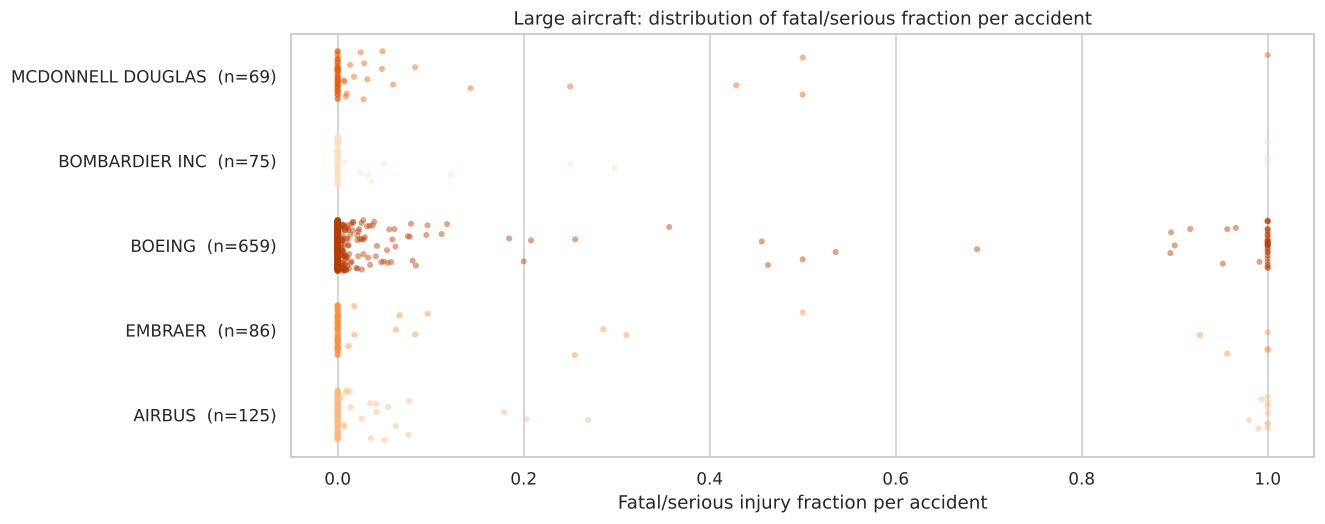

Share of accidents with zero fatal/serious injuries, and share above 50%:
                    zero  over_half
Make_clean                         
MCDONNELL DOUGLAS  0.710      0.014
BOMBARDIER INC     0.853      0.040
BOEING             0.777      0.056
EMBRAER            0.814      0.058
AIRBUS             0.760      0.080


In [7]:
top10_large = large_inj.head(10).index.tolist()
d = large[large['Make_clean'].isin(top10_large)].dropna(subset=['fatal_serious_fraction'])

fig, ax = plt.subplots(figsize=(12, 5))
sns.stripplot(data=d, x='fatal_serious_fraction', y='Make_clean', order=top10_large,
              hue='Make_clean', legend=False, palette='Oranges_r', alpha=0.45, jitter=0.3, size=4, ax=ax)
ax.set_yticks(range(len(top10_large)))
ax.set_yticklabels([f"{m}  (n={int(large_inj.loc[m, 'n'])})" for m in top10_large])
ax.set_title('Large aircraft: distribution of fatal/serious fraction per accident')
ax.set_xlabel('Fatal/serious injury fraction per accident'); ax.set_ylabel('')
save(fig, 'strip_large_makes'); plt.show()

print('Share of accidents with zero fatal/serious injuries, and share above 50%:')
print(d.groupby('Make_clean')['fatal_serious_fraction']
        .agg(zero=lambda s: (s == 0).mean(), over_half=lambda s: (s > 0.5).mean())
        .reindex(top10_large).round(3).to_string())

### 2.4 Rate of aircraft destruction by make (lowest 15)

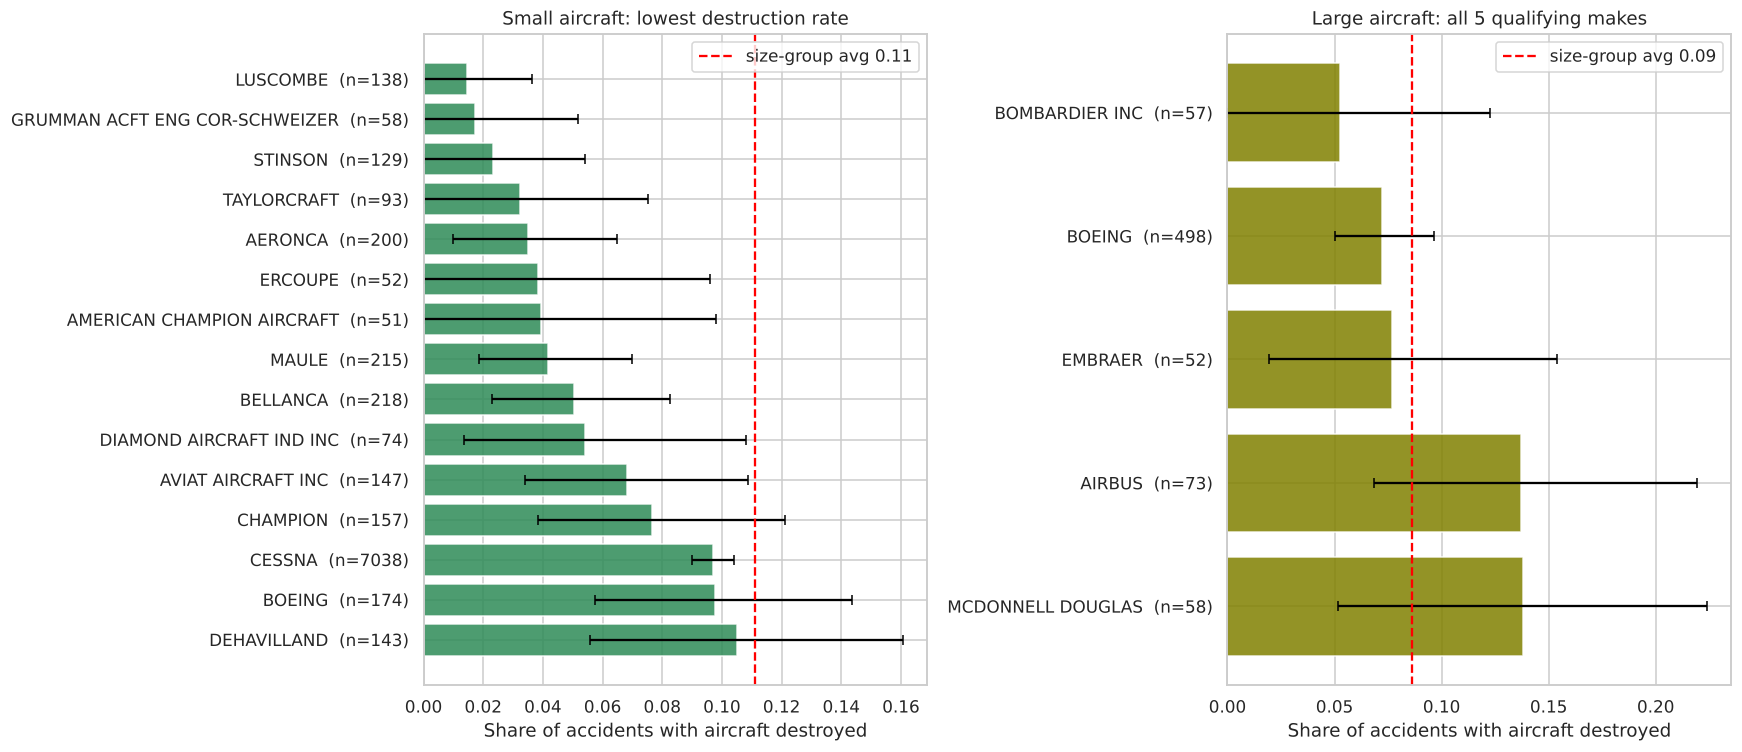

,mean,median,n,ci_low,ci_high,better_than_group_avg
Make_clean,,,,,,
LUSCOMBE,0.014,0.0,138,0.000,0.036,True
GRUMMAN ACFT ENG COR-SCHWEIZER,0.017,0.0,58,0.000,0.052,True
STINSON,0.023,0.0,129,0.000,0.054,True
TAYLORCRAFT,0.032,0.0,93,0.000,0.075,True
AERONCA,0.035,0.0,200,0.010,0.065,True
ERCOUPE,0.038,0.0,52,0.000,0.096,True
AMERICAN CHAMPION AIRCRAFT,0.039,0.0,51,0.000,0.098,True
MAULE,0.042,0.0,215,0.019,0.070,True
BELLANCA,0.050,0.0,218,0.023,0.083,True


,mean,median,n,ci_low,ci_high,better_than_group_avg
Make_clean,,,,,,
BOMBARDIER INC,0.053,0.0,57,0.000,0.123,False
BOEING,0.072,0.0,498,0.050,0.096,False
EMBRAER,0.077,0.0,52,0.019,0.154,False
AIRBUS,0.137,0.0,73,0.068,0.219,False
MCDONNELL DOUGLAS,0.138,0.0,58,0.052,0.224,False


Size-group average destruction rate: small 0.111, large 0.086


In [8]:
small_dest, small_dbase = group_table(small, 'Make_clean', 'destroyed', MIN_MAKE_N)
large_dest, large_dbase = group_table(large, 'Make_clean', 'destroyed', MIN_MAKE_N)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
barh_ci(axes[0], small_dest.head(15), 'Small aircraft: lowest destruction rate', 'Share of accidents with aircraft destroyed', 'seagreen')
axes[0].axvline(small_dbase, color='red', ls='--', label=f'size-group avg {small_dbase:.2f}'); axes[0].legend()
barh_ci(axes[1], large_dest.head(15), f'Large aircraft: all {len(large_dest)} qualifying makes', 'Share of accidents with aircraft destroyed', 'olive')
axes[1].axvline(large_dbase, color='red', ls='--', label=f'size-group avg {large_dbase:.2f}'); axes[1].legend()
plt.tight_layout(); save(fig, 'makes_destruction_rate'); plt.show()

display(small_dest.head(15).round(3))
display(large_dest.round(3))
print(f'Size-group average destruction rate: small {small_dbase:.3f}, large {large_dbase:.3f}')

### 2.5 Discussion: makes

**Sample sizes first.** With the 30-accident minimum, 29 small-aircraft makes qualify but only **5 large-aircraft makes** do (Boeing, Airbus, Embraer, Bombardier, McDonnell Douglas). The brief's "15 lowest" cannot be met for large aircraft; every qualifying make is shown instead. Rankings below that threshold would be driven by one or two accidents.

**Small aircraft: injury.**
- The size-group average is 0.289 fatal/serious fraction. The lowest means are Maule (0.165, n=215), Boeing (0.176, n=165), Aviat (0.196, n=148), Grumman/Schweizer (0.207, n=58), Ayres and Stinson (0.216).
- **"Boeing" here is not an airliner.** The aircraft types behind it are Boeing Stearman biplanes (A75N1/PT-17, B75N1, E75). It must not be read as evidence about Boeing jets.
- The confidence intervals overlap heavily. Maule's interval (0.119-0.214) is clearly below the group average, but it cannot be separated from the makes ranked 2nd to 8th. Treat the top group as a **tier**, not a strict ranking.
- Cessna (0.265, n=7,095, 44% of all small-aircraft accidents) ranks 12th of 29 and Piper (0.295, n=3,988) ranks 16th. Cessna is modestly better than the group average with a very tight interval; Piper is slightly worse. Neither is "very low".

**Small aircraft: distributions.** In the ten lowest-mean makes, 72-80% of accidents have *no* fatal or serious injuries and the median is 0 for every make. The differences between makes therefore come from the size of the tail (how often an accident is severe), not from a shifted typical accident.

**Large aircraft: injury.** The group average is 0.068. McDonnell Douglas (0.047, n=69), Bombardier (0.051, n=75), Boeing (0.062, n=659), Embraer (0.077, n=86) and Airbus (0.089, n=125) all have overlapping intervals, so **the data cannot rank them**. Boeing's estimate is by far the most precise (interval 0.045-0.080). In the strip plot, 71-85% of accidents have zero fatal/serious injuries for every make; the share of accidents above a 50% fatal/serious fraction is 1.4% for McDonnell Douglas, 4.0% Bombardier, 5.6% Boeing, 5.8% Embraer and 8.0% Airbus.

**Destruction rate.**
- *Small:* the size-group average is 0.111. Luscombe (0.014, n=138), Grumman/Schweizer (0.017, n=58), Stinson (0.023), Taylorcraft (0.032), Aeronca (0.035) and Maule (0.042) are lowest, all well below Cessna (0.097, n=7,038). These are mostly light, older tail-draggers; a plausible reason is lower speed and weight, which this notebook does not test.
- *Large:* the group average is 0.086. Bombardier (0.053, n=57), Boeing (0.072, n=498) and Embraer (0.077, n=52) are lowest; Airbus (0.137, n=73) and McDonnell Douglas (0.138, n=58) are highest, but their intervals (0.068-0.219 and 0.052-0.224) overlap with the others, so the difference is suggestive, not established.

### 2.6 Analyzing plane types (make + model)
Only aircraft types with **at least 10 accidents inside their size group** are kept. For small aircraft, plotted types are further limited to the 10 lowest-injury makes found above, as the brief asks.

Types with n >= 10 inside size group: small 335, large 16


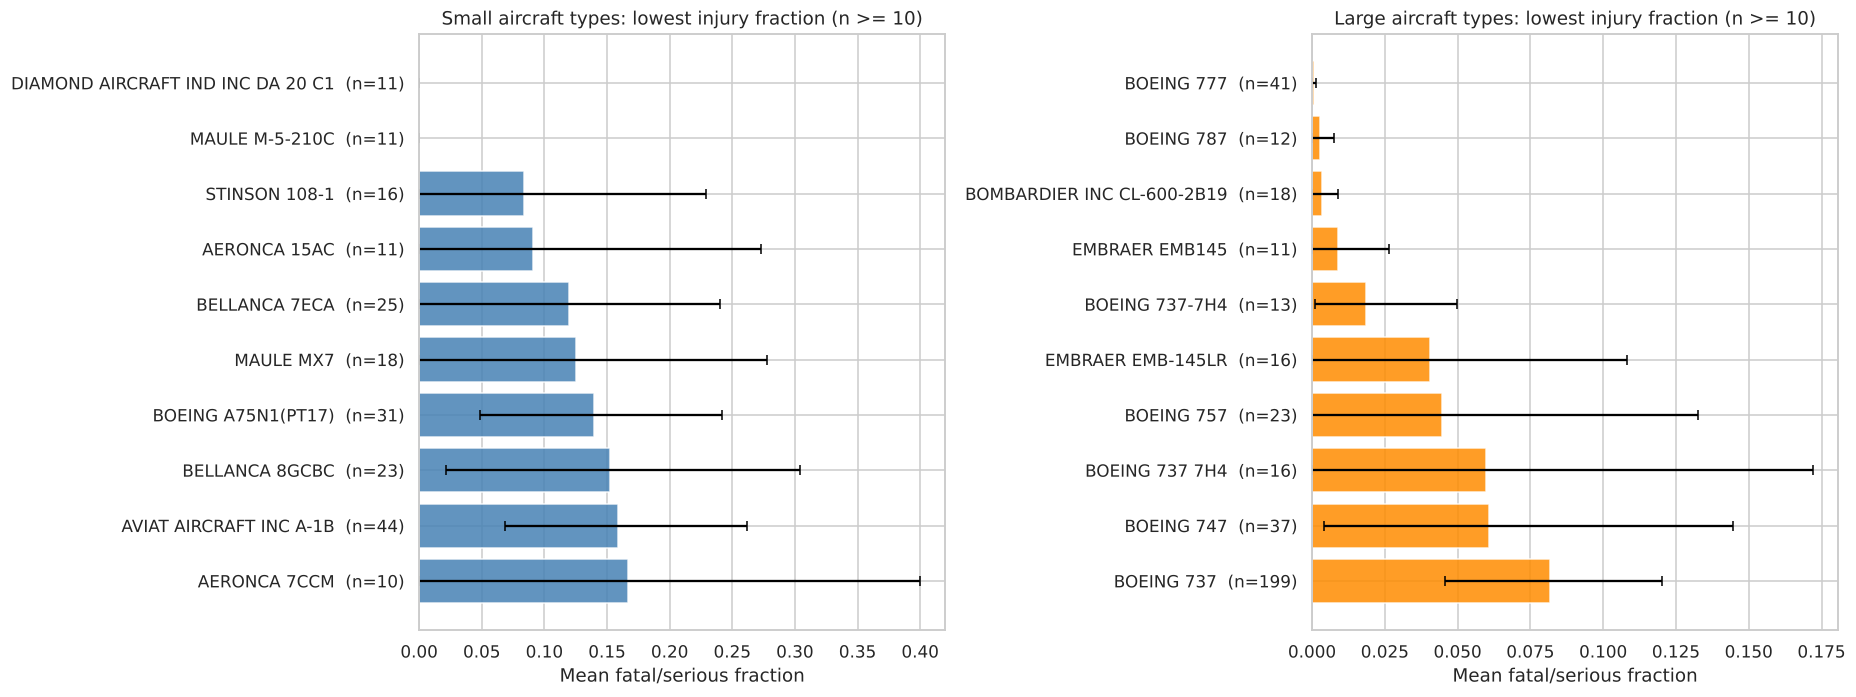

,mean,n,ci_low,ci_high,make,share_any_fatal_serious,share_any_upper95
make_model,,,,,,,
DIAMOND AIRCRAFT IND INC DA 20 C1,0.000,11,0.000,0.000,DIAMOND AIRCRAFT IND INC,0.000,0.259
MAULE M-5-210C,0.000,11,0.000,0.000,MAULE,0.000,0.259
STINSON 108-1,0.083,16,0.000,0.229,STINSON,0.125,0.360
AERONCA 15AC,0.091,11,0.000,0.273,AERONCA,0.091,0.377
BELLANCA 7ECA,0.120,25,0.000,0.240,BELLANCA,0.120,0.300
MAULE MX7,0.125,18,0.000,0.278,MAULE,0.167,0.392
BOEING A75N1(PT17),0.140,31,0.048,0.242,BOEING,0.226,0.398
BELLANCA 8GCBC,0.152,23,0.022,0.304,BELLANCA,0.174,0.371
AVIAT AIRCRAFT INC A-1B,0.159,44,0.068,0.261,AVIAT AIRCRAFT INC,0.205,0.345


,mean,n,ci_low,ci_high,share_any_fatal_serious,share_any_upper95
make_model,,,,,,
BOEING 777,0.001,41,0.000,0.001,0.098,0.225
BOEING 787,0.003,12,0.000,0.008,0.167,0.448
BOMBARDIER INC CL-600-2B19,0.003,18,0.000,0.009,0.111,0.328
EMBRAER EMB145,0.009,11,0.000,0.026,0.091,0.377
BOEING 737-7H4,0.018,13,0.001,0.050,0.308,0.576
EMBRAER EMB-145LR,0.041,16,0.000,0.108,0.188,0.430
BOEING 757,0.045,23,0.000,0.133,0.130,0.321
BOEING 737 7H4,0.060,16,0.000,0.172,0.125,0.360
BOEING 747,0.061,37,0.004,0.145,0.135,0.280


In [9]:
small_mod, _ = group_table(small, 'make_model', 'fatal_serious_fraction', MIN_MODEL_N)
large_mod, _ = group_table(large, 'make_model', 'fatal_serious_fraction', MIN_MODEL_N)

# restrict small types to the 10 lowest-injury makes
small_mod['make'] = small.drop_duplicates('make_model').set_index('make_model').loc[small_mod.index, 'Make_clean']
small_mod_top = small_mod[small_mod['make'].isin(top10_small)].head(10)
large_mod_top = large_mod.head(10)

# Bootstrap intervals collapse to [0, 0] when every accident has zero injuries, so for types we also report
# the share of accidents with ANY fatal/serious injury and its Wilson 95% upper bound (honest at small n).
def add_any_share(tab, data):
    d = data.dropna(subset=['fatal_serious_fraction'])
    out = []
    for m in tab.index:
        x = d.loc[d['make_model'] == m, 'fatal_serious_fraction']
        k, n = int((x > 0).sum()), len(x)
        ci = stats.binomtest(k, n).proportion_ci(confidence_level=0.95, method='wilson')
        out.append((k / n, ci.high))
    tab['share_any_fatal_serious'] = [o[0] for o in out]
    tab['share_any_upper95'] = [o[1] for o in out]
    return tab

print(f'Types with n >= {MIN_MODEL_N} inside size group: small {len(small_mod)}, large {len(large_mod)}')

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
barh_ci(axes[0], small_mod_top, 'Small aircraft types: lowest injury fraction (n >= 10)', 'Mean fatal/serious fraction', 'steelblue')
barh_ci(axes[1], large_mod_top, 'Large aircraft types: lowest injury fraction (n >= 10)', 'Mean fatal/serious fraction', 'darkorange')
plt.tight_layout(); save(fig, 'models_injury_fraction'); plt.show()

small_mod_top = add_any_share(small_mod_top.copy(), small)
large_mod_top = add_any_share(large_mod_top.copy(), large)
display(small_mod_top.drop(columns=['better_than_group_avg', 'median']).round(3))
display(large_mod_top.drop(columns=['better_than_group_avg', 'median']).round(3))

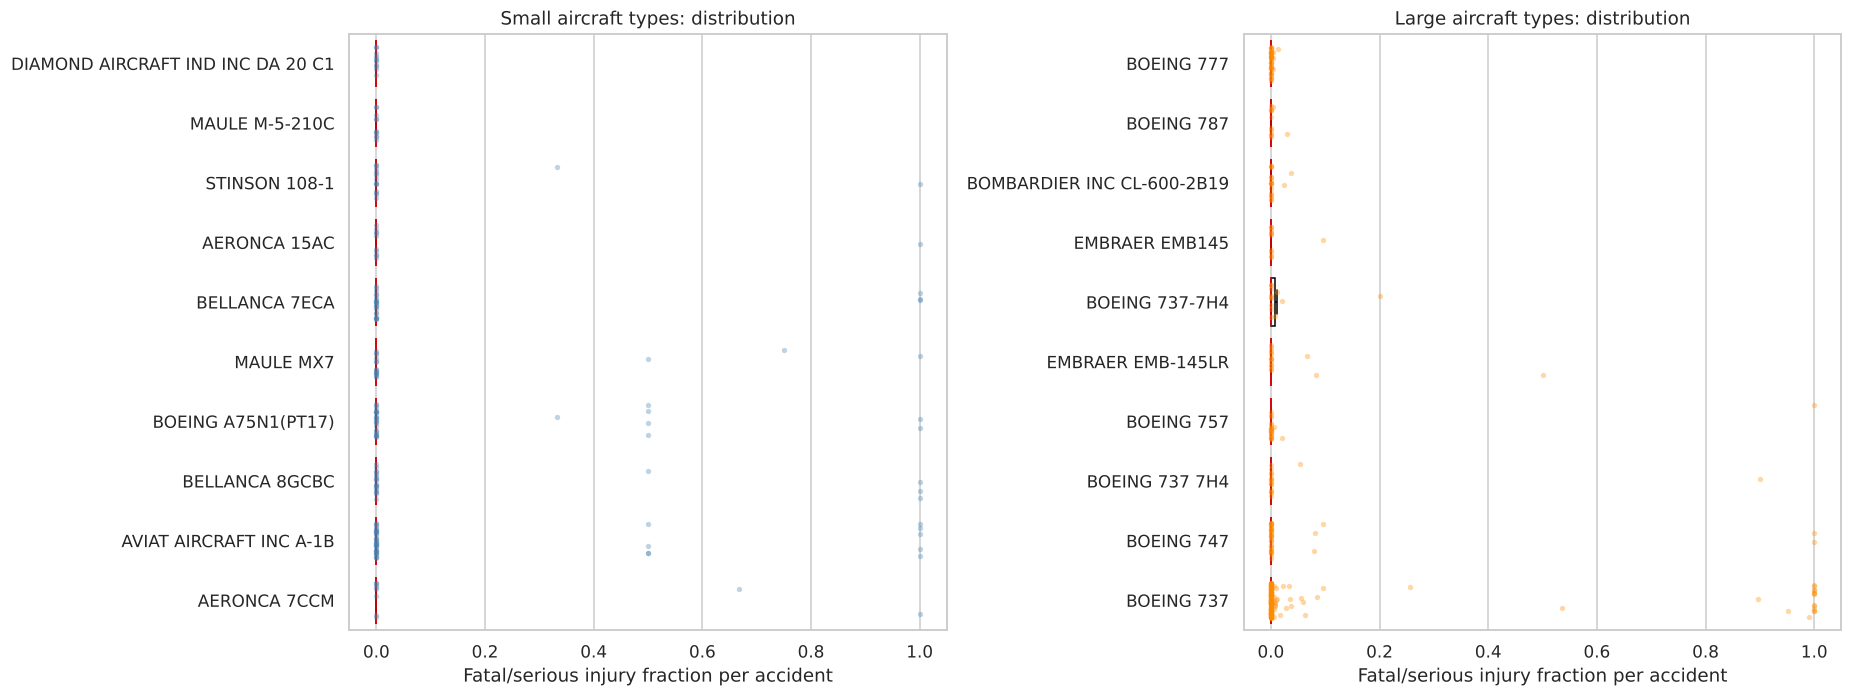

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, tab, data, col in [(axes[0], small_mod_top, small, 'steelblue'), (axes[1], large_mod_top, large, 'darkorange')]:
    order = tab.index.tolist()
    sub = data[data['make_model'].isin(order)].dropna(subset=['fatal_serious_fraction'])
    sns.stripplot(data=sub, x='fatal_serious_fraction', y='make_model', order=order, color=col,
                  alpha=0.35, jitter=0.3, size=3.5, ax=ax)
    sns.boxplot(data=sub, x='fatal_serious_fraction', y='make_model', order=order, showfliers=False,
                boxprops=dict(facecolor='none', edgecolor='black'), whiskerprops=dict(color='black'),
                capprops=dict(color='black'), medianprops=dict(color='red'), ax=ax)
    ax.set_xlabel('Fatal/serious injury fraction per accident'); ax.set_ylabel('')
axes[0].set_title('Small aircraft types: distribution'); axes[1].set_title('Large aircraft types: distribution')
plt.tight_layout(); save(fig, 'models_injury_distribution'); plt.show()

### 2.7 Discussion: specific airplane types

**Filter used.** Types need at least 10 accidents *inside their size group*: 335 small types and only **16 large types** qualify. For small aircraft, plotted types are restricted to the ten lowest-injury makes. Because bootstrap intervals collapse to [0, 0] when every accident had zero injuries, the tables also show the **share of accidents with any fatal/serious injury** and its Wilson 95% upper bound, which is honest at small n.

**Small aircraft types.**
- The lowest means belong to the Diamond DA-20 C1 and the Maule M-5-210C (both 0.000), but each rests on only **11 accidents**; the upper 95% bound on the share of accidents with any serious injury is still 26%, so "zero" is not proof of safety.
- Better-supported candidates have more accidents behind them: the Aviat A-1B (0.159, n=44, interval 0.068-0.261), the Boeing Stearman A75N1/PT-17 (0.140, n=31), the Bellanca 7ECA (0.120, n=25) and the Bellanca 8GCBC (0.152, n=23).
- All ten intervals overlap, so these are **shortlist candidates**, not a proven ranking. The Cessna 152 and Piper PA-28 do not appear among the lowest-injury types.

**Large aircraft types.**
- The Boeing 777 (0.001, n=41), 787 (0.003, n=12), Bombardier CL-600-2B19, the CRJ-200 regional jet (0.003, n=18) and Embraer EMB145 (0.009, n=11) have the lowest means.
- **Caution:** the fraction divides by everyone on board, so one serious injury on a 300-seat aircraft scores about 0.003 while the same injury on a 4-seat aircraft scores 0.25. This favours large aircraft mechanically. About 10% of 777 accidents (9.8%, upper bound 22.5%) still involved at least one fatal/serious injury.
- The most precisely measured large types are the 737 (0.082, n=199; 19.6% of accidents with any serious injury, upper bound 25.7%), 777 (n=41) and 747 (0.061, n=37). Only the 737 estimate is tight. 737 variants appear as separate keys (e.g. "737", "737-7H4"), which splits its sample; merging them would be a judgement left for a later iteration.

## STEP 3: Exploring other variables
Two factors are analyzed: **weather condition** and **engine type**. Both are available for most records after cleaning and both are plausible drivers of outcome severity. Because aircraft size strongly affects the outcome, the comparisons are made **within the small-aircraft group** (where the sample is large enough), and the overall picture is shown for context. The `Unknown` category is kept visible rather than dropped.

### Factor 1: Weather condition

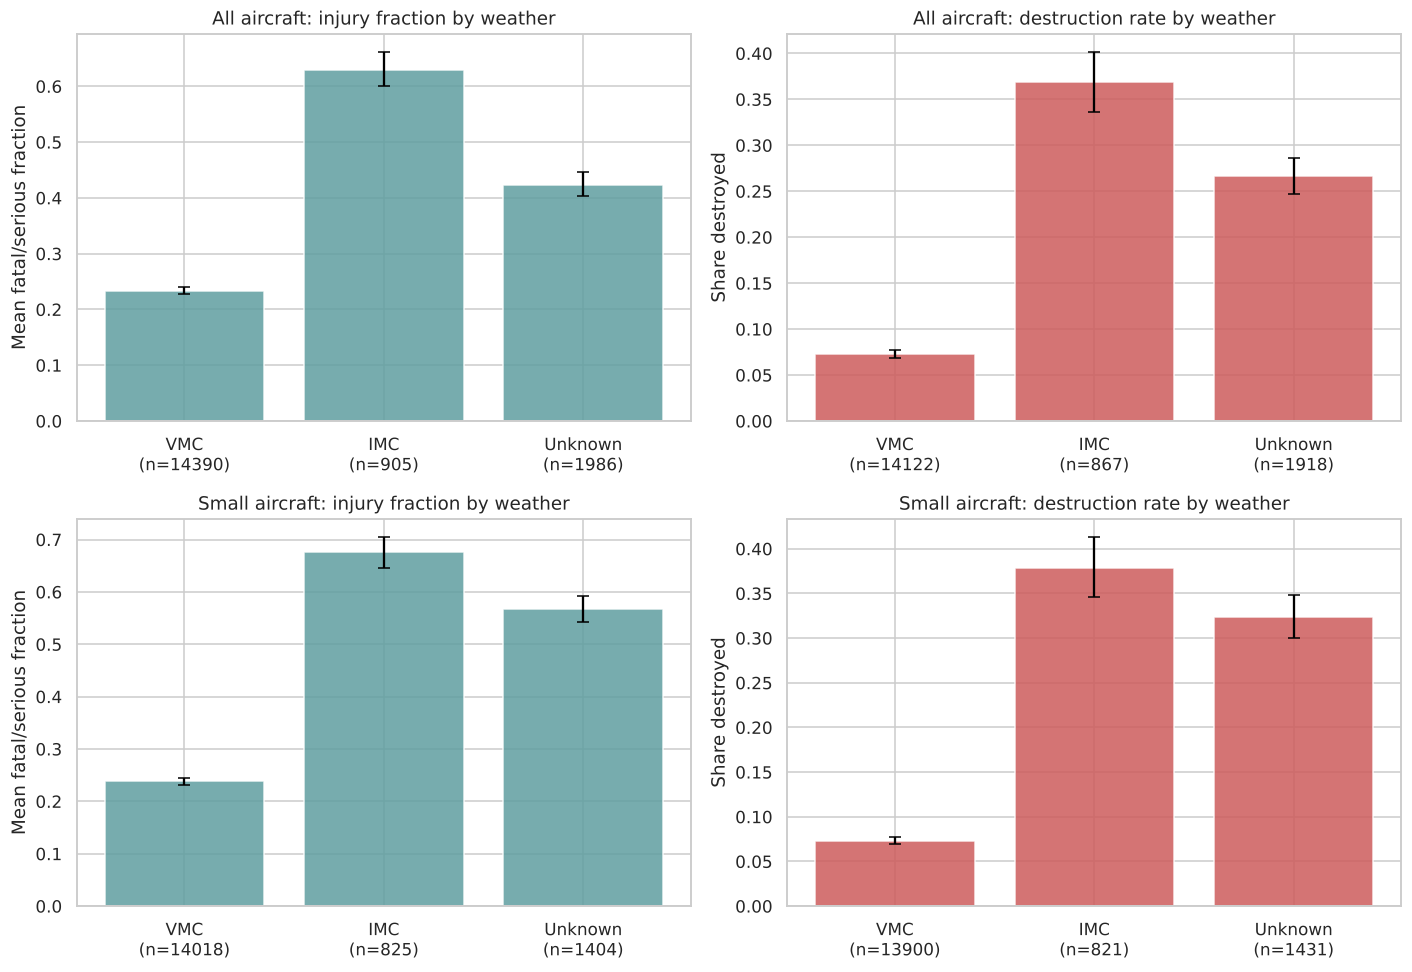

All aircraft    VMC n=14390 mean=0.234 | IMC n= 905 mean=0.629 | Mann-Whitney p=1.10e-166 | destroyed VMC=0.073 IMC=0.369, chi-square p=5.44e-192
Small aircraft  VMC n=14018 mean=0.239 | IMC n= 825 mean=0.676 | Mann-Whitney p=2.02e-174 | destroyed VMC=0.073 IMC=0.379, chi-square p=1.19e-192
Large aircraft  VMC n=  372 mean=0.037 | IMC n=  80 mean=0.145 | Mann-Whitney p=1.84e-05 | destroyed VMC=0.036 IMC=0.196, chi-square p=2.07e-04


In [11]:
def level_table(data, col, value_col, levels, min_n=1):
    d = data.dropna(subset=[value_col])
    rows = []
    for lv in levels:
        x = d.loc[d[col] == lv, value_col]
        if len(x) >= min_n:
            lo, hi = boot_ci(x)
            rows.append((lv, len(x), x.mean(), lo, hi))
    return pd.DataFrame(rows, columns=[col, 'n', 'mean', 'ci_low', 'ci_high']).set_index(col)

def ci_bars(ax, tab, title, ylabel, color):
    x = np.arange(len(tab))
    err = [tab['mean'] - tab['ci_low'], tab['ci_high'] - tab['mean']]
    ax.bar(x, tab['mean'], yerr=err, color=color, alpha=0.85, capsize=4, ecolor='black')
    ax.set_xticks(x); ax.set_xticklabels([f'{i}\n(n={n})' for i, n in zip(tab.index, tab['n'])])
    ax.set_title(title); ax.set_ylabel(ylabel)

w_levels = ['VMC', 'IMC', 'Unknown']
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for r, (name, data) in enumerate([('All aircraft', df), ('Small aircraft', small)]):
    ci_bars(axes[r, 0], level_table(data, 'Weather.Condition', 'fatal_serious_fraction', w_levels),
            f'{name}: injury fraction by weather', 'Mean fatal/serious fraction', 'cadetblue')
    ci_bars(axes[r, 1], level_table(data, 'Weather.Condition', 'destroyed', w_levels),
            f'{name}: destruction rate by weather', 'Share destroyed', 'indianred')
plt.tight_layout(); save(fig, 'factor_weather'); plt.show()

for name, data in [('All aircraft', df), ('Small aircraft', small), ('Large aircraft', large)]:
    v = data.loc[data['Weather.Condition'] == 'VMC']; i = data.loc[data['Weather.Condition'] == 'IMC']
    vi, ii = v['fatal_serious_fraction'].dropna(), i['fatal_serious_fraction'].dropna()
    u = stats.mannwhitneyu(vi, ii) if min(len(vi), len(ii)) > 0 else None
    vd, idd = v['destroyed'].dropna(), i['destroyed'].dropna()
    tbl = [[int(vd.sum()), int((1 - vd).sum())], [int(idd.sum()), int((1 - idd).sum())]]
    chi = stats.chi2_contingency(tbl)[1] if min(len(vd), len(idd)) > 0 and min(sum(tbl[0]), sum(tbl[1])) > 0 else np.nan
    print(f'{name:15s} VMC n={len(vi):5d} mean={vi.mean():.3f} | IMC n={len(ii):4d} mean={ii.mean() if len(ii) else float("nan"):.3f}'
          f' | Mann-Whitney p={u.pvalue if u else float("nan"):.2e}'
          f' | destroyed VMC={vd.mean():.3f} IMC={idd.mean() if len(idd) else float("nan"):.3f}, chi-square p={chi:.2e}')

### Weather: discussion

**Finding: accidents in instrument conditions (IMC) are far more severe than in visual conditions (VMC), for both size groups.**

| Group | Fatal/serious fraction VMC | IMC | Destroyed VMC | IMC |
|---|---|---|---|---|
| Small aircraft | 0.239 (n=14,018) | 0.676 (n=825) | 0.073 | 0.379 |
| Large aircraft | 0.037 (n=372) | 0.145 (n=80) | 0.036 | 0.196 |

- In small aircraft an IMC accident has about **2.8 times** the injury fraction and **5 times** the destruction rate. Both differences are statistically overwhelming (Mann-Whitney p ~ 2e-174; chi-square p ~ 1e-192).
- The effect holds in large aircraft too (injury p = 1.8e-5, destruction p = 2.1e-4), with a smaller sample (80 IMC accidents), so the gap is real but less precisely sized.
- The `Unknown` weather category has a high injury fraction (0.42 across all aircraft, n=1,986), so it is not simply a random subset of VMC; the VMC/IMC comparison should not be extended to it.
- **Interpretation:** the data only contains accidents. IMC accidents are a minority of accidents (about 5-6% of small-aircraft accidents with known weather) but are much deadlier once they happen, consistent with loss of control and flight into terrain when visual references are lost. This is an association, not a measured per-flight risk.

### Factor 2: Engine type

Accidents with a known outcome by engine type, split by size:
size           Large  Small
Engine.Type                
Reciprocating      1  12957
Turbo Prop        36    905
Turbo Fan        528    201
Turbo Jet         44     27
Turbo Shaft        0      9
Unknown          956   2408


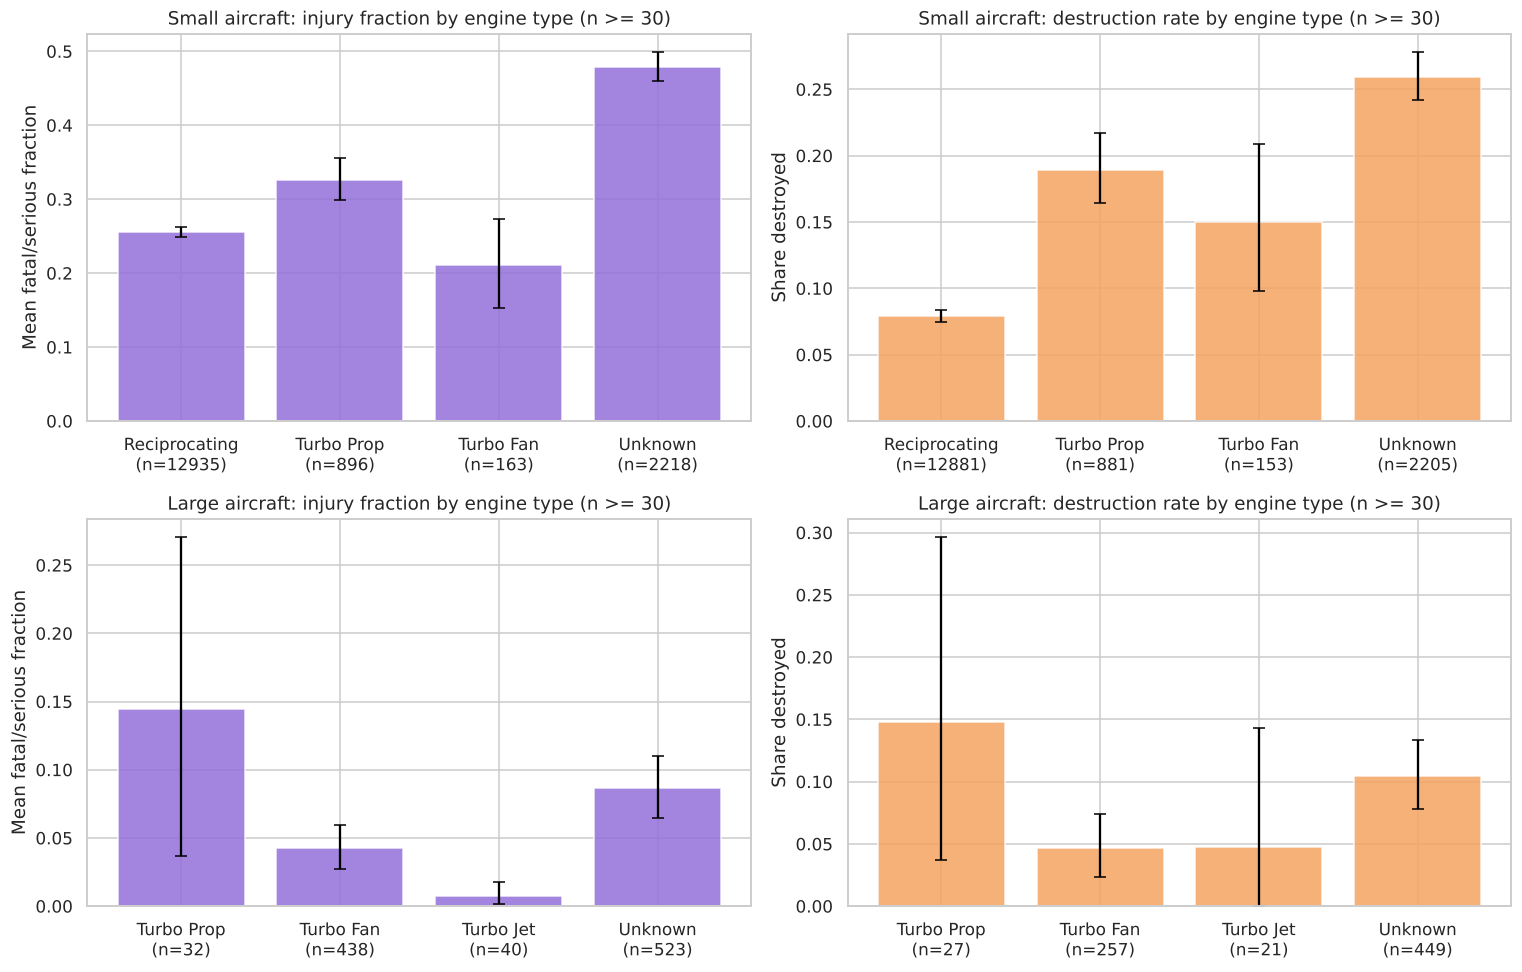

In [12]:
eng_order = ['Reciprocating', 'Turbo Prop', 'Turbo Fan', 'Turbo Jet', 'Turbo Shaft', 'Unknown']
print('Accidents with a known outcome by engine type, split by size:')
print(pd.crosstab(df['Engine.Type'], df['size']).reindex(eng_order).to_string())

MIN_ENG_N = 30
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for r, (name, data) in enumerate([('Small aircraft', small), ('Large aircraft', large)]):
    keep = [e for e in eng_order if (data['Engine.Type'] == e).sum() >= MIN_ENG_N]
    ci_bars(axes[r, 0], level_table(data, 'Engine.Type', 'fatal_serious_fraction', keep),
            f'{name}: injury fraction by engine type (n >= {MIN_ENG_N})', 'Mean fatal/serious fraction', 'mediumpurple')
    ci_bars(axes[r, 1], level_table(data, 'Engine.Type', 'destroyed', keep),
            f'{name}: destruction rate by engine type (n >= {MIN_ENG_N})', 'Share destroyed', 'sandybrown')
plt.tight_layout(); save(fig, 'factor_engine'); plt.show()

In [13]:
# Statistical tests, small aircraft, known engine types with n >= 30 each
d = small[small['Engine.Type'].isin(['Reciprocating', 'Turbo Prop', 'Turbo Fan'])]
groups = {k: g['fatal_serious_fraction'].dropna() for k, g in d.groupby('Engine.Type')}
print('Kruskal-Wallis (injury fraction) across engine types: p = %.2e' % stats.kruskal(*groups.values()).pvalue)
print('\nPairwise vs Reciprocating (Mann-Whitney, Bonferroni x2):')
for k in ['Turbo Prop', 'Turbo Fan']:
    p = min(1, stats.mannwhitneyu(groups[k], groups['Reciprocating']).pvalue * 2)
    print(f'  {k:11s} mean={groups[k].mean():.3f} (n={len(groups[k])}) vs Reciprocating mean={groups["Reciprocating"].mean():.3f}: p = {p:.2e}')

print('\nLarge aircraft by engine type (known outcomes):')
for e in ['Turbo Fan', 'Turbo Prop', 'Turbo Jet']:
    x = large[large['Engine.Type'] == e]
    print(f'  {e:10s} injury: n={x["fatal_serious_fraction"].notna().sum():4d} mean={x["fatal_serious_fraction"].mean():.3f}'
          f' | destroyed: n={x["destroyed"].notna().sum():4d} mean={x["destroyed"].mean():.3f}')
print('All aircraft pooled (pooled across both size groups):')
print(df.groupby('Engine.Type')['fatal_serious_fraction'].mean().reindex(['Reciprocating', 'Turbo Prop', 'Turbo Fan']).round(3).to_string())

print('\nDestruction rate, small aircraft:')
dd = d.dropna(subset=['destroyed'])
tab = pd.crosstab(dd['Engine.Type'], dd['destroyed'])
print((tab[1] / tab.sum(axis=1)).round(3).to_string())
print('Chi-square across the three engine types: p = %.2e' % stats.chi2_contingency(tab)[1])

Kruskal-Wallis (injury fraction) across engine types: p = 4.06e-07

Pairwise vs Reciprocating (Mann-Whitney, Bonferroni x2):
  Turbo Prop  mean=0.327 (n=896) vs Reciprocating mean=0.255: p = 4.45e-07
  Turbo Fan   mean=0.210 (n=163) vs Reciprocating mean=0.255: p = 2.86e-01

Large aircraft by engine type (known outcomes):
  Turbo Fan  injury: n= 438 mean=0.043 | destroyed: n= 257 mean=0.047
  Turbo Prop injury: n=  32 mean=0.144 | destroyed: n=  27 mean=0.148
  Turbo Jet  injury: n=  40 mean=0.008 | destroyed: n=  21 mean=0.048
All aircraft pooled (pooled across both size groups):
Engine.Type
Reciprocating    0.255
Turbo Prop       0.320
Turbo Fan        0.088

Destruction rate, small aircraft:
Engine.Type
Reciprocating    0.079
Turbo Fan        0.150
Turbo Prop       0.190
Chi-square across the three engine types: p = 7.79e-30


### Engine type: discussion

**The pooled comparison is misleading; compare within a size group.** Across *all* aircraft, turbo fans look far safer (0.088 injury fraction) than reciprocating engines (0.255). That mostly reflects aircraft **size**: turbo fans power the large jets, whose fraction is diluted by hundreds of occupants. A naive reading, that turbofan/turbojet engines have vastly lower injury *and* destruction rates, does not hold up: pooled across sizes, turbo jets are destroyed in 25% of accidents (only 44 known outcomes, so suggestive rather than conclusive) and turbo props have the highest injury fraction of any known engine type (0.320).

**Small aircraft (n large enough for tests):**

| Engine | Fatal/serious fraction | Destruction rate |
|---|---|---|
| Reciprocating | 0.255 (n=12,935) | 0.079 |
| Turbo Prop | 0.327 (n=896) | 0.190 |
| Turbo Fan | 0.210 (n=163) | 0.150 |

- Turbo props have a **significantly higher injury fraction** than reciprocating engines (Bonferroni-adjusted p = 4.5e-7). Turbo fans are not significantly different from reciprocating (p = 0.29).
- Destruction differs strongly across engine types (chi-square p ~ 8e-30): reciprocating-engine aircraft are destroyed least often (7.9%). Turbine aircraft are faster and heavier, which plausibly explains more destructive accidents, though that is not tested here.

**Large aircraft:** turbo fans dominate (injury 0.043, n=438; destruction 0.047, n=257). Turbo props show 0.144 injury (n=32) and 0.148 destruction (n=27), and turbo jets 0.008 injury (n=40) but only 21 known destruction outcomes. Those last groups are too small for firm conclusions.

**Caveat:** about 3,400 accidents have an unknown engine type and a high injury fraction (0.40 overall), so engine-type findings describe the known-engine subset only.

## Summary: recommendations
Makes that combine a low injury fraction **and** a low destruction rate, ranked by the average of the two ranks. Only makes that clear the sample-size rule appear.

In [14]:
def combined(inj, dest):
    t = inj[['mean', 'n', 'ci_low', 'ci_high']].join(dest[['mean', 'n']], lsuffix='_injury', rsuffix='_destroyed', how='inner')
    t['rank_injury'] = t['mean_injury'].rank(); t['rank_destroyed'] = t['mean_destroyed'].rank()
    t['avg_rank'] = (t['rank_injury'] + t['rank_destroyed']) / 2
    return t.sort_values('avg_rank')[['n_injury', 'mean_injury', 'ci_low', 'ci_high', 'n_destroyed', 'mean_destroyed', 'avg_rank']]

print('SMALL aircraft: combined ranking (top 8)')
display(combined(small_inj, small_dest).head(8).round(3))
print('LARGE aircraft: combined ranking (all qualifying makes)')
display(combined(large_inj, large_dest).round(3))

SMALL aircraft: combined ranking (top 8)


,n_injury,mean_injury,ci_low,ci_high,n_destroyed,mean_destroyed,avg_rank
Make_clean,,,,,,,
GRUMMAN ACFT ENG COR-SCHWEIZER,58,0.207,0.103,0.310,58,0.017,3.0
MAULE,215,0.165,0.119,0.214,215,0.042,4.5
STINSON,129,0.216,0.154,0.282,129,0.023,4.5
AVIAT AIRCRAFT INC,148,0.196,0.139,0.257,147,0.068,7.0
LUSCOMBE,141,0.280,0.209,0.355,138,0.014,7.5
AERONCA,200,0.226,0.172,0.283,200,0.035,7.5
BOEING,165,0.176,0.126,0.228,174,0.098,8.0
BELLANCA,219,0.223,0.171,0.277,218,0.050,8.0


LARGE aircraft: combined ranking (all qualifying makes)


,n_injury,mean_injury,ci_low,ci_high,n_destroyed,mean_destroyed,avg_rank
Make_clean,,,,,,,
BOMBARDIER INC,75,0.051,0.014,0.101,57,0.053,1.5
BOEING,659,0.062,0.045,0.080,498,0.072,2.5
MCDONNELL DOUGLAS,69,0.047,0.015,0.088,58,0.138,3.0
EMBRAER,86,0.077,0.031,0.128,52,0.077,3.5
AIRBUS,125,0.089,0.046,0.139,73,0.137,4.5


### Recommendations

**Small aircraft (recommend with moderate confidence).** Aim for makes that are low on both measures and well supported: **Maule** (injury 0.165, destruction 0.042, n=215), **Aviat** (0.196 / 0.068, n=148), **Stinson** (0.216 / 0.023, n=129), **Aeronca** (0.226 / 0.035, n=200) and **Bellanca** (0.223 / 0.050, n=219). Grumman/Schweizer has the best combined rank (destruction 0.017) but only 58 accidents and a wide injury interval (0.103-0.310). Among very large fleets, **Cessna** is a safe, well-measured default (0.265 / 0.097, n about 7,000), whereas Piper is slightly worse than average. Two warnings: the "Boeing" small-aircraft entry is the vintage Stearman biplane, not a jet; and several low-risk makes (Stinson, Aeronca, Luscombe, Taylorcraft) are legacy types, so the client should check how many are still in service and insurable. Small differences between neighbouring makes are not statistically distinguishable.

**Large aircraft (recommend with lower confidence).** **Boeing** is the best-supported choice: low injury (0.062) and destruction (0.072) with the tightest intervals (n=659 and 498). **Bombardier** edges Boeing on both measures and **Embraer** is comparable (0.077 / 0.077), but each rests on only 52-86 accidents. **McDonnell Douglas** has the lowest injury fraction (0.047) but a high destruction rate (0.138). **Airbus** has the highest injury fraction of the five (0.089) and a destruction rate of 0.137, though its interval overlaps the others. Specific types with the best evidence are the **Boeing 777, 787 and 737** and the **Bombardier CL-600-2B19**; no make in the large group is statistically separable from the rest.

**Two supported risk factors.** (1) **Instrument weather conditions** multiply injury fraction by about 2.8 and destruction rate by about 5 in small aircraft, and roughly 4 times for injury and 5 times for destruction in large aircraft. (2) **Engine type matters only within a size class**: among small aircraft turbo props carry significantly higher injury and destruction rates than piston engines, and the apparent advantage of turbofans in pooled data is a size effect.

### Limitations
- Every figure is conditional on an accident having been recorded. A make with very many flights will show many accidents; a make with few accidents may simply fly less. Without flight-hour exposure data this analysis cannot give per-flight risk.
- Occupancy is the number of people counted in the accident record, not seat capacity, so the small/large split is a proxy. Counts of zero occupants are excluded from the size classification.
- Roughly 5% of injury outcomes and 6% of damage outcomes are unknown and were excluded from the statistics that use them.
- Only five makes have enough large-aircraft accidents to be compared, so the large-aircraft recommendations are far less granular than the small-aircraft ones.
- Weather and engine type are observational comparisons; they do not isolate cause (for example IMC accidents also tend to involve different phases of flight and pilots).